# Assessment of Snow Depth Retrievability from Passive Microwave Observations over Arctic Sea Ice: A Global Sensitivity Analysis

__Ziyu Yan__, __Yufang Ye__, __Xiao Cheng__: School of Geospatial Engineering and Science, Sun Yat-sen University, Zhuhai, China; Southern Marine Science and Engineering Guangdong Laboratory (Zhuhai), Zhuhai, China; Key Laboratory of Comprehensive Observation of Polar Environment (Sun Yat-sen University), Ministry of Education, Zhuhai, China

__Georg Heygster__: Institute of Environmental Physics, University of Bremen, Bremen, Germany

__Bin Cheng__: Finnish Meteorological Institute, Helsinki, Finland

__Carolina Gabarró__, __Ferran Hernández-Macià__: Barcelona Polar Lab, Institute of Marine Sciences, Barcelona, Spain

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

> **Source.** Built from the published paper, *The Cryosphere* 20(11), 6157–6180 (30 October 2026, doi:[10.5194/tc-20-6157-2026](https://doi.org/10.5194/tc-20-6157-2026), CC BY 4.0), and its Supplement; page, table and figure numbers refer to that version. An earlier build used the EGUsphere preprint (doi:[10.5194/egusphere-2026-1680](https://doi.org/10.5194/egusphere-2026-1680)); Tables 1 and 4 and the numbers in Fig. 3a are the same in both.

The paper runs the Snow Microwave Radiative Transfer model SMRT [[2]](https://doi.org/10.5194/gmd-11-2763-2018) on snow over Arctic sea ice and ranks the snow parameters by EFAST variance-based indices for the 12 AMSR2 channels. It reports no active subspace. Here we regenerate its single-layer dry-snow case (five inputs, Table 1) with SMRT 1.5.1, the version and settings its Supplement gives (Table S1), and ask whether the brightness temperatures vary mostly along a few directions of the input space. The notebook runs in Python 3 with numpy, scipy, matplotlib and [active_subspaces](https://github.com/paulcon/active_subspaces) 1.0; it reads the stored data and does not need SMRT. Kind: **stored data, generated with SMRT 1.5.1; regeneration script included** (`snow_smrt_model.py`, `generate_data.py`; see `DATA.md`).

In [1]:
%matplotlib inline
import time
from itertools import combinations_with_replacement

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import snow_smrt_model as sm      # constants only; SMRT itself is imported lazily and is not needed here

SEED = 424                        # the only seed in this notebook (also the seed of generate_data.py)
t_start = time.perf_counter()
names = list(sm.NAMES)
labels = ['depth $d$', r'density $\rho$', 'temperature $T$', 'radius $r$', r'stickiness $\tau$']

### Summary

The brightness temperatures that SMRT computes for one dry snow layer on first-year sea ice depend on five snow inputs (depth, density, temperature, grain radius and stickiness, on the ranges of the paper's Table 1), and we regenerated them with SMRT 1.5.1 in the paper's configuration at 400 Monte Carlo samples with finite-difference gradients. For $T_B$ at 36.5 GHz V the first eigenvalue of the gradient matrix holds 77.9 % of the trace ($\lambda_1/\lambda_2 = 7.54$) and the first two 88.2 %; the first eigenvector mixes stickiness, grain radius, density and depth, a cubic in two active variables has leave-one-out $R^2 = 0.857$ (0.927 without the 41 samples above 458.35 kg m$^{-3}$, where the paper's dense-snow correction makes $T_B$ jump), and GR(36/18) has practically the same subspace. The 6.9 and 10.7 GHz H channels are one-dimensional in density ($\lambda_1/\lambda_2 = 2151$ and 455), and Sobol' indices estimated from the same data give the same leading parameter as the paper's EFAST results (Fig. 3a) in all 12 channels.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ inputs normalized to $[-1,1]^m$ with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and little along $\mathbf W_2^T\mathbf x$; a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) then shows the main trend, and a low-dimensional surrogate in $\mathbf y$ can stand in for $f$. We estimate $\mathbf C$ by the average of $\nabla f\nabla f^T$ over Monte Carlo samples and judge the estimate by bootstrap intervals. See Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM 2015 [[3]](https://doi.org/10.1137/1.9781611973860).

### The model

**Snowpack.** One dry snow layer of thickness $d$, density $\rho$, temperature $T$, effective grain radius $r$ and stickiness $\tau$ lies on first-year sea ice (paper Sect. 2.1, 3.3, 3.4, pp. 6158–6163). The snow microstructure is a sticky hard sphere medium (spheres of radius $r$ at ice volume fraction $\phi = \rho/\rho_{\mathrm{ice}}$, $\rho_{\mathrm{ice}} = 916.7$ kg m$^{-3}$ in SMRT, with stickiness $\tau$; smaller $\tau$ means stickier grains). Its absorption and scattering coefficients $\kappa_a$, $\kappa_s$ and phase matrix $\mathbf P$ come from the improved Born approximation (IBA) with SMRT's dense-snow correction (Supplement Table S1): for $\phi > 0.5$ (density above 458.35 kg m$^{-3}$) the medium is inverted, air spheres in ice instead of ice spheres in air. The ice column is two layers, 0.5 m and 1.0 m thick, at 265 K with 5 % brine inclusions of radius 0.1 mm (Table 4, p. 6166), over a water substrate (Table S1).

**Radiative transfer.** SMRT solves, in each layer, the radiative transfer equation for the Stokes intensity $\mathbf I(z, \mu)$,
$$\mu\frac{d\mathbf I}{dz} = -\kappa_e \mathbf I + \kappa_a B(T) + \int_{4\pi}\mathbf P(\mu,\mu')\,\mathbf I(z,\mu')\,d\Omega', \qquad \kappa_e = \kappa_a + \kappa_s,$$
with Fresnel reflection and transmission at flat interfaces (the paper treats all interfaces as smooth, Sect. 4.3, p. 6175; Table S1), by the discrete ordinates and eigenvalue method (DORT, Table S1). The output is the upwelling brightness temperature $T_B$ at the snow–air interface, without atmosphere, at incidence $55^\circ$, for the AMSR2 frequencies 6.925, 10.65, 18.7, 23.8, 36.5 and 89 GHz in vertical (V) and horizontal (H) polarization (paper Sect. 2.1 and 3.1, pp. 6159 and 6161).

**Quantities of interest.** The headline QoI is $T_B$ at 36.5 GHz V (36V), the channel most snow-depth algorithms use. The second is the gradient ratio (paper Eq. 12, p. 6160)
$$\mathrm{GR}(36/18) = \frac{T_B(36\mathrm V) - T_B(18\mathrm V)}{T_B(36\mathrm V) + T_B(18\mathrm V)},$$
the basis of the Markus and Cavalieri snow-depth algorithm [[5]](https://doi.org/10.1029/AR074p0019). The paper does not say which polarization its GRs use; we take V, as Markus and Cavalieri do. The stored data hold all 12 channels.

**Inputs.** Independent uniform on the ranges of the paper's Table 1 (p. 6163); the paper states that its EFAST sampling assumes uniform distributions on these ranges (Sect. 3.3, p. 6162). The cell below prints the table from the code's names and bounds, and the held settings. From the Supplement (Table S1): SMRT 1.5.1, IBA with the dense-snow correction, sticky hard spheres, flat (Fresnel) interfaces, a water substrate below the ice, DORT, and SMRT's default permittivity models. **Settings the paper does not state** are chosen here and listed in `DATA.md`: DORT's stream settings (SMRT's defaults, 32 streams), no snow salinity, the ice microstructure (sticky hard spheres with $\tau = 0.3$, the paper's value for superimposed ice) and the water substrate's properties (SMRT's default).

In [2]:
print(f"{'input':12s} {'units':8s} {'lower':>7s} {'upper':>7s}  source")
for n, u, lo, hi in zip(names, sm.UNITS, sm.LOWER, sm.UPPER):
    print(f'{n:12s} {u:8s} {lo:7.3g} {hi:7.3g}  Yan et al. (2026), Table 1, single-layer dry snow; uniform')
print('\nheld settings (snow_smrt_model.CONFIG):')
for k, v in sm.CONFIG.items():
    print(f'  {k}: {v}')
print('\nchannels:', ', '.join(sm.CHANNELS), '(GHz:', sm.FREQ_GHZ, ')')

input        units      lower   upper  source
depth        m              0     0.6  Yan et al. (2026), Table 1, single-layer dry snow; uniform
density      kg m^-3      150     500  Yan et al. (2026), Table 1, single-layer dry snow; uniform
temperature  K            240     270  Yan et al. (2026), Table 1, single-layer dry snow; uniform
radius       mm           0.1     0.4  Yan et al. (2026), Table 1, single-layer dry snow; uniform
stickiness   -            0.1     0.3  Yan et al. (2026), Table 1, single-layer dry snow; uniform

held settings (snow_smrt_model.CONFIG):
  smrt_version: 1.5.1
  emmodel: iba
  emmodel_options: {'dense_snow_correction': 'auto'}
  rtsolver: dort
  rtsolver_options: {}
  theta_deg: 55.0
  snow_microstructure: sticky_hard_spheres
  snow_salinity: 0.0
  permittivity_models: SMRT 1.5.1 defaults
  interfaces: flat
  atmosphere: None
  ice_type: firstyear
  ice_thickness_m: [0.5, 1.0]
  ice_temperature_K: 265.0
  ice_density_kg_m3: 910.0
  ice_brine_volume_fract

### Load data

`generate_data.py` drew $M = 400$ Monte Carlo samples (numpy `default_rng(424)`, independent uniform on the box) and ran SMRT 1.5.1 at each sample and at a finite-difference stencil: central differences with step $10^{-4}$ of each input's half-range, or a second-order one-sided stencil where the central one would leave the box, 11 SMRT runs per sample. It took 573 s (9.6 min) on two processes (`DATA.md`). The files hold the physical inputs, the 12 brightness temperatures, their gradients with respect to the physical inputs, and a flag array described next.

In [3]:
X = np.loadtxt('inputs.csv', delimiter=',')                              # (M, 5) physical inputs
TB = np.loadtxt('outputs.csv', delimiter=',')                            # (M, 12) TB in K
G = np.loadtxt('gradients.csv', delimiter=',').reshape(len(X), 12, 5)    # dTB/dx, physical units
J = np.loadtxt('fd_jumps.csv', delimiter=',').astype(int)                # (M, 12) stencil-jump bitmask
print(f'inputs {X.shape}, outputs {TB.shape}, gradients {G.shape}, jump flags {J.shape}')

inputs (400, 5), outputs (400, 12), gradients (400, 12, 5), jump flags (400, 12)


Four features of this SMRT configuration matter for the data. (i) **Dense-snow step.** The dense-snow correction switches the IBA medium at density 458.35 kg m$^{-3}$, and $T_B$ is discontinuous there. Direct SMRT runs (`DATA.md`, "Accuracy") give a jump at 36.5 GHz V of $-6.83$ K at the midpoint of the other inputs and up to $-54.0$ K at the deep, coarse-grained corner ($-41.7$ K at 89 GHz V at the midpoint); from the stored data alone the notebook estimates the 36V jump at $-7.50$ K at the midpoint (printed in the section "The dense-snow step and the gradient matrix" below). The paper's range reaches 500 kg m$^{-3}$, so 41 of the 400 samples lie above the step. **No finite-difference gradient straddles it:** the nearest sample is 0.246 kg m$^{-3}$ from the threshold, 14 times the density step of 0.0175 kg m$^{-3}$, and no sample is within 10 steps (next cell). Each stored gradient is therefore a one-sided, pathwise derivative: the derivative of the smooth branch on the sample's own side of the threshold. $\hat{\mathbf C}$, built from these gradients on each side, does not capture the jump itself; the values do. (ii) **Stream-count jumps.** DORT sets the number of streams in the snow layer from the snow's refractive index, so the count changes in steps as density, and slightly temperature, change, and $T_B$ jumps by about 0.1 K across those surfaces. A central stencil that straddles a jump of either kind gives a meaningless derivative; `generate_data.py` detects this by comparing the two one-sided slopes and keeps the smaller one, and `fd_jumps.csv` records where. (iii) **Zero depth.** SMRT drops a layer of zero thickness, and $T_B$ is discontinuous there: at the midpoint of the other inputs, 6.9 GHz H is 197.58 K for bare ice and 228.47 K for a 0.1 µm snow layer (`DATA.md`), because a snow layer of any thickness adds an air–snow and a snow–ice Fresnel interface, combined incoherently. Uniform samples have $d > 0$ with probability one and the stencils stay inside $(0, 0.6]$ m, so the data describe the limit $d \to 0^+$. (iv) **Thin layers.** Because the interfaces are combined incoherently, layers much thinner than a wavelength (centimetres) already carry the full $+30$ K H-pol offset: $T_B$ for $d$ from $10^{-7}$ to $10^{-3}$ m is the same within 0.02 K below 89 GHz. This is unphysical for such layers but is what the paper's configuration computes; 9 samples have $d < 1$ cm and 19 have $d < 3$ cm. The cell counts these cases and the flagged stencils, prints the distance from the dense-snow threshold to the nearest sample against the finite-difference step, and forms the two quantities of interest.

In [4]:
M = len(X)
ch = {c: k for k, c in enumerate(sm.CHANNELS)}
dense = X[:, 1] > sm.DENSE_THRESHOLD
print(f'samples with density > {sm.DENSE_THRESHOLD:.2f} kg/m^3 (ice fraction > 0.5; dense-snow correction, '
      f'inverted medium): {dense.sum()} of {M}')
h_rho = 1e-4 * (sm.UPPER[1] - sm.LOWER[1]) / 2   # finite-difference step in density (generate_data.py), kg/m^3
dist = np.abs(X[:, 1] - sm.DENSE_THRESHOLD)
print(f'nearest sample to the threshold: {dist.min():.3f} kg/m^3 (sample {dist.argmin()}, '
      f'{"above" if X[dist.argmin(), 1] > sm.DENSE_THRESHOLD else "below"}), {dist.min() / h_rho:.0f} times the '
      f'FD density step {h_rho:.4f} kg/m^3; samples within 10 steps: {np.count_nonzero(dist < 10 * h_rho)}, '
      f'within 100 steps: {np.count_nonzero(dist < 100 * h_rho)}; so no stencil straddles the threshold')
print(f'samples with depth < 1 cm: {np.count_nonzero(X[:, 0] < 0.01)}, < 3 cm: {np.count_nonzero(X[:, 0] < 0.03)}')
print(f'smallest depth {X[:, 0].min():.2e} m; inputs inside the box: {np.all((X >= sm.LOWER) & (X <= sm.UPPER))}')
print(f'TB range over all channels [{TB.min():.1f}, {TB.max():.1f}] K; all finite: {np.isfinite(TB).all() & np.isfinite(G).all()}')
print('stencil jumps detected (sample, channel entries) per channel:',
      ', '.join(f'{c} {np.count_nonzero(J[:, k])}' for c, k in ch.items()))
print(f'samples with a jump in any channel: {np.count_nonzero(J.any(axis=1))}; '
      f'in 36V or 18V: {np.count_nonzero(J[:, [ch["36V"], ch["18V"]]].any(axis=1))}')

# the two quantities of interest: TB at 36.5 GHz V, and GR(36/18) = (TB36V - TB18V)/(TB36V + TB18V)
tb36, tb18 = TB[:, ch['36V']], TB[:, ch['18V']]
f36, G36 = tb36, G[:, ch['36V']]
fgr = (tb36 - tb18) / (tb36 + tb18)
Ggr = (2 * tb18[:, None] * G[:, ch['36V']] - 2 * tb36[:, None] * G[:, ch['18V']]) / (tb36 + tb18)[:, None]**2
print(f'TB36V: mean {f36.mean():.2f} K, sd {f36.std(ddof=1):.2f} K, range [{f36.min():.1f}, {f36.max():.1f}] K')
print(f'TB18V: mean {tb18.mean():.2f} K, sd {tb18.std(ddof=1):.2f} K, range [{tb18.min():.1f}, {tb18.max():.1f}] K')
print(f'GR(36/18): mean {fgr.mean():.4f}, sd {fgr.std(ddof=1):.4f}, range [{fgr.min():.4f}, {fgr.max():.4f}]')
print(f'TB36V mean over samples below / above the dense-snow threshold: {f36[~dense].mean():.1f} / {f36[dense].mean():.1f} K')

samples with density > 458.35 kg/m^3 (ice fraction > 0.5; dense-snow correction, inverted medium): 41 of 400
nearest sample to the threshold: 0.246 kg/m^3 (sample 321, above), 14 times the FD density step 0.0175 kg/m^3; samples within 10 steps: 0, within 100 steps: 6; so no stencil straddles the threshold
samples with depth < 1 cm: 9, < 3 cm: 19
smallest depth 6.84e-05 m; inputs inside the box: True
TB range over all channels [91.7, 265.1] K; all finite: True
stencil jumps detected (sample, channel entries) per channel: 6V 0, 6H 0, 10V 0, 10H 0, 18V 0, 18H 0, 23V 0, 23H 0, 36V 0, 36H 0, 89V 1, 89H 1
samples with a jump in any channel: 1; in 36V or 18V: 0
TB36V: mean 251.42 K, sd 12.48 K, range [189.1, 263.4] K
TB18V: mean 259.96 K, sd 1.47 K, range [251.7, 262.3] K
GR(36/18): mean -0.0173, sd 0.0235, range [-0.1419, 0.0028]
TB36V mean over samples below / above the dense-snow threshold: 251.3 / 252.6 K


### Estimate the subspace

SMRT is not differentiable here, but it is deterministic and cheap enough for finite differences, so we use the gradient-based estimator (`estimator="as"`), $\hat{\mathbf C} = \frac1M\sum_i \nabla f_i\nabla f_i^T$ in normalized coordinates. The step study in `DATA.md` (8 samples, steps $3\times10^{-5}$ and $3\times10^{-4}$) shows the stored gradients agree with a smaller step to a per-channel relative error of at most $1.3\times10^{-4}$ (median $8\times10^{-7}$); the worst case is a sharp but smooth feature at one sample. **What $\hat{\mathbf C}$ measures here.** $T_B$ is piecewise smooth, with a jump across the plane $\rho = 458.35$ kg m$^{-3}$. $\hat{\mathbf C}$ is the average of the pathwise gradients, those of the smooth branch on each side, so it describes the smooth variation within each side and not the jump. No average of gradients can represent the jump: its derivative is a delta function on that plane, so $\int\nabla f\,\nabla f^T\rho\,d\mathbf x$ of the discontinuous $T_B$ is infinite along the density axis, and smoothing the step over any finite width would make density dominate $\mathbf C$ (printed in the section on the step below). We use the pathwise matrix deliberately, and report separately how the 41 samples above the step change it (after the subspace errors). All inputs are uniform, so each is scaled the same way, by its own half-range, through `ac.Uniform(lower, upper)`; we pass physical inputs and physical gradients and the library normalizes once. We take 500 bootstrap replicates with seed `SEED`, and orient each eigenvector so that $T_B$ increases along it on average.

In [5]:
space = ac.Uniform(sm.LOWER, sm.UPPER, names=names)     # every input scaled by its own half-range to [-1, 1]
sub = ac.active_subspace(space=space, X=X, f=f36, grads=G36, estimator='as', nboot=500,
                         bootstrap_vectors=2, rng=SEED, qoi='TB36V')
sub = ac.orient(sub, by='mean_gradient', grads=G36, columns=2)   # TB36V increases along w1 on average
lam, W = sub.eigenvalues, sub.eigenvectors
ks, crit, k_hat = ac.dimension_criterion(sub, rule='evg')
lo, hi = ac.bootstrap_interval(sub.bootstrap_eigenvalues)
print('eigenvalues:', np.array2string(lam, precision=4))
print('95 % bootstrap intervals:', ', '.join(f'[{a:.3g}, {b:.3g}]' for a, b in zip(lo, hi)))
print(f'n = {sub.n} (eigenvalue-gap rule picks {k_hat}); lambda1/lambda2 = {lam[0] / lam[1]:.2f}, '
      f'lambda2/lambda3 = {lam[1] / lam[2]:.2f}, lambda3/lambda4 = {lam[2] / lam[3]:.2f}, '
      f'lambda4/lambda5 = {lam[3] / lam[4]:.1f}; '
      f'lambda1 share of trace {lam[0] / lam.sum():.3f}, lambda1+lambda2 {lam[:2].sum() / lam.sum():.3f}')

eigenvalues: [945.8692 125.3912  88.7472  51.7376   2.609 ]
95 % bootstrap intervals: [710, 1.2e+03], [81.5, 179], [62.7, 109], [32.6, 67.8], [2.13, 3.01]
n = 1 (eigenvalue-gap rule picks 1); lambda1/lambda2 = 7.54, lambda2/lambda3 = 1.41, lambda3/lambda4 = 1.72, lambda4/lambda5 = 19.8; lambda1 share of trace 0.779, lambda1+lambda2 0.882


/tmp/ipykernel_9916/1279638951.py:2: AccuracyWarning: bootstrap eigenvector replicates are poorly aligned with the full-sample vectors (columns [1]); their components are ill-defined, e.g. near repeated eigenvalues [accuracy.unaligned_replicates]
  sub = ac.active_subspace(space=space, X=X, f=f36, grads=G36, estimator='as', nboot=500,


### Results for $T_B$(36V)

**Eigenvalues**, with 95 % bootstrap bands.

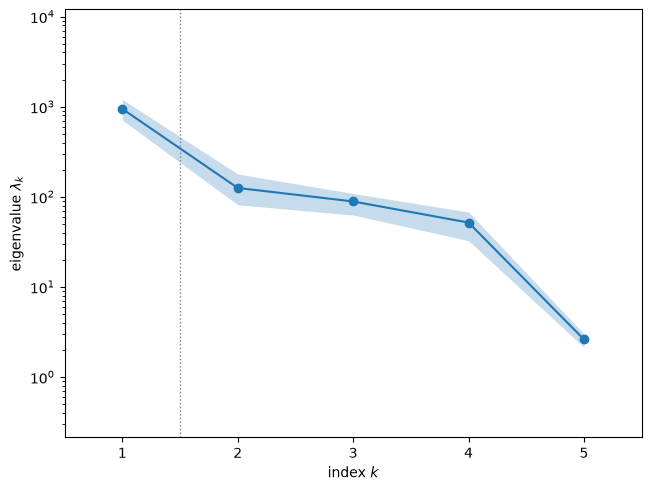

In [6]:
fig, ax = ac.plotting.plot_eigenvalues(sub)
plt.close(fig)
fig

$\lambda_1 = 946$ (95 % bootstrap interval 710–1200) is 7.54 times $\lambda_2 = 125$ (81.5–179), and the eigenvalue-gap rule picks $n = 1$. The next ratios are small, $\lambda_2/\lambda_3 = 1.41$ and $\lambda_3/\lambda_4 = 1.72$, so after the first direction the variation spreads over three more. That holds only with the 41 samples above the dense-snow step included: below the step alone $\lambda_2/\lambda_3$ is 2.14 (printed after the subspace errors). The smallest eigenvalue, $\lambda_5 = 2.61$, is 19.8 times smaller than $\lambda_4$: its eigenvector is almost pure temperature (next cell), so the snow temperature over 240–270 K changes $T_B$(36V) little.

bootstrap mean subspace distance, k = 1..4: [0.067 0.302 0.188 0.02 ]


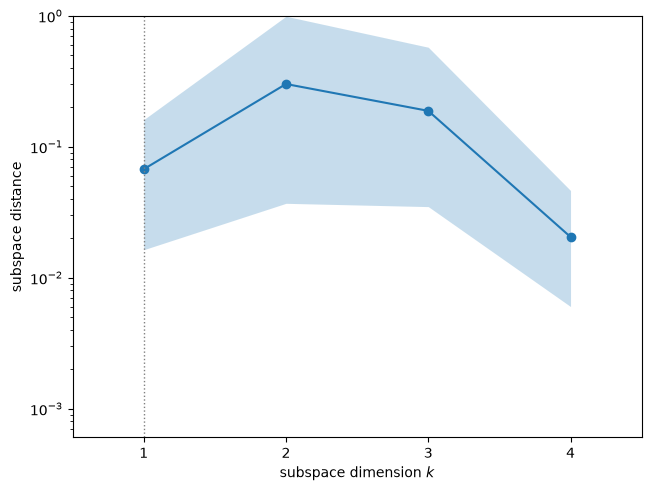

In [7]:
fig, ax = ac.plotting.plot_subspace_errors(sub)
plt.close(fig)
print('bootstrap mean subspace distance, k = 1..4:',
      np.array2string(sub.bootstrap_distances.mean(axis=0), precision=3))
fig

The bootstrap mean subspace distance is 0.067 for $n = 1$, 0.302 for $n = 2$, 0.188 for $n = 3$ and 0.02 for $n = 4$ (the complement of the temperature direction). The first eigenvector is well determined by the 400 samples; the second is not, and the library warns that the bootstrap replicates of $\mathbf w_2$ are poorly aligned, because $\lambda_2$ and $\lambda_3$ differ by a factor of only 1.41.

In [8]:
# the same estimator on the samples below the dense-snow threshold only, and (few samples) above it
sub_b = ac.active_subspace(space=space, X=X[~dense], f=f36[~dense], grads=G36[~dense], estimator='as',
                           nboot=500, rng=SEED, qoi='TB36V, below the threshold')
sub_b = ac.orient(sub_b, by='mean_gradient', grads=G36[~dense], columns=1)
sub_a = ac.active_subspace(space=space, X=X[dense], f=f36[dense], grads=G36[dense], estimator='as')
sub_a = ac.orient(sub_a, by='mean_gradient', grads=G36[dense], columns=1)
print('sample set     n    lambda1/lambda2 [95 %]   lambda2/lambda3 [95 %]   lambda1 share   '
      'w1 (d, rho, T, r, tau)               |w1 . w1(all)|')
for nm, s, rows in [('all', sub, np.ones(M, bool)), ('below', sub_b, ~dense), ('above', sub_a, dense)]:
    l_ = s.eigenvalues
    if s.bootstrap_eigenvalues is not None:
        bl = s.bootstrap_eigenvalues
        q12, q23 = np.percentile(bl[:, 0] / bl[:, 1], [2.5, 97.5]), np.percentile(bl[:, 1] / bl[:, 2], [2.5, 97.5])
        i12, i23 = f'[{q12[0]:.2f}, {q12[1]:.2f}]', f'[{q23[0]:.2f}, {q23[1]:.2f}]'
    else:
        i12 = i23 = '(no bootstrap)'
    print(f'{nm:9s} {rows.sum():5d}    {l_[0] / l_[1]:5.2f} {i12:14s}    {l_[1] / l_[2]:5.2f} {i23:14s}   '
          f'{l_[0] / l_.sum():.3f}        (' + ', '.join(f'{v:+.3f}' for v in s.eigenvectors[:, 0])
          + f')   {abs(s.eigenvectors[:, 0] @ W[:, 0]):.4f}')
g_rho = G36[:, 1] * (sm.UPPER[1] - sm.LOWER[1]) / 2      # dTB36V/d(normalized density), K
print(f'mean dTB36V/dx_rho (normalized): {g_rho[~dense].mean():+.1f} K below the threshold, '
      f'{g_rho[dense].mean():+.1f} K above')


sample set     n    lambda1/lambda2 [95 %]   lambda2/lambda3 [95 %]   lambda1 share   w1 (d, rho, T, r, tau)               |w1 . w1(all)|
all         400     7.54 [5.77, 9.92]       1.41 [1.08, 2.18]     0.779        (-0.339, +0.379, +0.066, -0.533, +0.673)   1.0000
below       359     7.53 [5.95, 12.00]      2.14 [1.19, 3.48]     0.809        (-0.328, +0.404, +0.062, -0.515, +0.678)   0.9995
above        41     8.74 (no bootstrap)     6.47 (no bootstrap)   0.881        (-0.430, -0.415, +0.134, -0.738, +0.283)   0.5813
mean dTB36V/dx_rho (normalized): +9.1 K below the threshold, -6.1 K above


**The headline with and without the samples above the step.** On the 359 samples below the threshold, $\lambda_1/\lambda_2 = $ 7.53 (95 % bootstrap interval [5.95, 12.00]), against 7.54 ([5.77, 9.92]) for all 400, and $\mathbf w_1$ hardly moves: $|\mathbf w_1\cdot\mathbf w_1^{\mathrm{all}}| = $ 0.9995. The second ratio changes: $\lambda_2/\lambda_3$ is 2.14 ([1.19, 3.48]) below the step and 1.41 ([1.08, 2.18]) with all samples. So the 41 samples above the step change $\lambda_2/\lambda_3$ (1.41 → 2.14) but not $\mathbf w_1$; the two bootstrap intervals overlap, so the shift is of the size of the sampling uncertainty of $\lambda_2/\lambda_3$, but it has a clear cause. Above the step the medium is inverted and the local behaviour differs: the mean normalized density derivative of $T_B$(36V) is $+9.1$ K below and $-6.1$ K above, and the first eigenvector of the 41 dense samples alone has density weight $-0.415$ ($|\mathbf w_1\cdot\mathbf w_1^{\mathrm{all}}| = $ 0.5813; 41 samples are fewer than the 10 m = 50 we ask for, so this is only indicative). Averaging two smooth branches with different gradients fills in $\lambda_2$ and $\lambda_3$, so the near-equal $\lambda_2 \approx \lambda_3$ of the headline is partly an effect of the dense branch, while the leading direction is robust to it. The headline keeps all 400 samples because they are the paper's set-up (density up to 500 kg m$^{-3}$, Table 1).

w1: depth -0.339, density +0.379, temperature +0.066, radius -0.533, stickiness +0.673
w2: depth -0.362, density +0.327, temperature +0.114, radius -0.455, stickiness -0.737
w5: depth -0.053, density -0.056, temperature +0.981, radius +0.173, stickiness +0.046
activity scores (n = 2), share of lambda1 + lambda2: depth 0.117, density 0.139, temperature 0.005, radius 0.275, stickiness 0.464
mean |dTB36V/dx_tau| (normalized): 25.2 K for tau < 0.15, 2.1 K for tau > 0.25


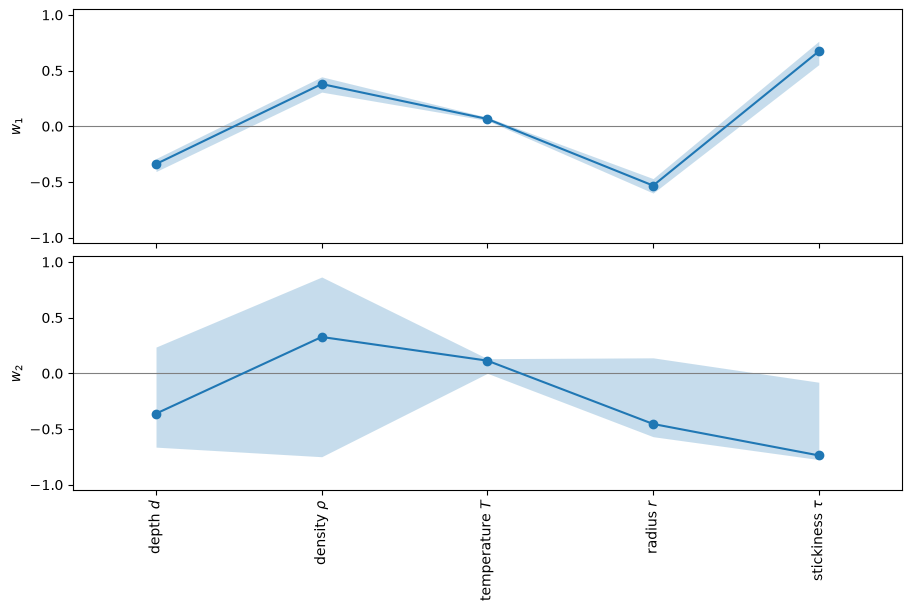

In [9]:
fig, axes = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=labels, interval='percentile',
                                          figsize=(9, 6))
plt.close(fig)
for j in [0, 1, 4]:
    print(f'w{j + 1}:', ', '.join(f'{n} {v:+.3f}' for n, v in zip(names, W[:, j])))
alpha = (W[:, :2]**2) @ lam[:2]          # activity scores of the two-dimensional subspace
print('activity scores (n = 2), share of lambda1 + lambda2:',
      ', '.join(f'{n} {a / lam[:2].sum():.3f}' for n, a in zip(names, alpha)))
g_tau = G36[:, 4] * (sm.UPPER[4] - sm.LOWER[4]) / 2       # dTB36V/d(normalized stickiness), K
print(f'mean |dTB36V/dx_tau| (normalized): {np.abs(g_tau[X[:, 4] < 0.15]).mean():.1f} K for tau < 0.15, '
      f'{np.abs(g_tau[X[:, 4] > 0.25]).mean():.1f} K for tau > 0.25')
fig

$\mathbf w_1$ weights stickiness by $+0.673$, grain radius by $-0.533$, density by $+0.379$, depth by $-0.339$ and temperature by $+0.066$. The depth, radius and stickiness signs are those of volume scattering: $T_B$ falls with deeper snow and larger grains and rises with less sticky grains (larger $\tau$, less scattering in the sticky hard sphere model); at 36 GHz it also rises with density. $\mathbf w_2$ has similar depth, density and radius weights but the opposite stickiness weight ($-0.737$). With $n = 2$, stickiness carries 46.4 % of $\lambda_1 + \lambda_2$, radius 27.5 %, density 13.9 %, depth 11.7 % and temperature 0.5 %; $\mathbf w_5$ is temperature with weight $0.981$. In the gradient-based measure stickiness leads, while in variance-based indices (comparison below) radius leads: the effect of $\tau$ is steep near $\tau = 0.1$ and flat near 0.3 (mean $|\partial T_B/\partial x_\tau|$ 25.2 K for $\tau < 0.15$ against 2.1 K for $\tau > 0.25$, in normalized units), and a derivative that large on part of the range raises the mean squared derivative more than the share of the variance.

corr(TB36V, y1) below / above the dense-snow threshold: 0.761 / 0.758
TB36V for y1 > 0 (193 samples): 10th percentile 255.6 K, max 263.4 K, min 226.2 K (a dense sample: True)
y1 range [-1.42, 1.61]; corr(TB36V, y1) = 0.735


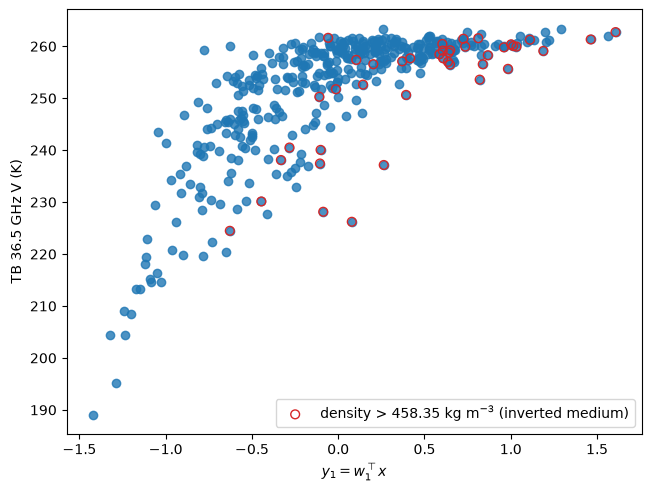

In [10]:
Y = space.to_normalized(X) @ W[:, :2]
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=X, f=f36, dims=1, qoi_label='TB 36.5 GHz V (K)')
ax.scatter(Y[dense, 0], f36[dense], s=40, facecolors='none', edgecolors='tab:red',
           label=f'density > {sm.DENSE_THRESHOLD:.2f} kg m$^{{-3}}$ (inverted medium)')
ax.legend(loc='lower right')
plt.close(fig)
print(f'corr(TB36V, y1) below / above the dense-snow threshold: {np.corrcoef(f36[~dense], Y[~dense, 0])[0, 1]:.3f} / '
      f'{np.corrcoef(f36[dense], Y[dense, 0])[0, 1]:.3f}')
pos = Y[:, 0] > 0
print(f'TB36V for y1 > 0 ({np.count_nonzero(pos)} samples): 10th percentile {np.percentile(f36[pos], 10):.1f} K, '
      f'max {f36[pos].max():.1f} K, min {f36[pos].min():.1f} K (a dense sample: {dense[pos][np.argmin(f36[pos])]})')
print(f'y1 range [{Y[:, 0].min():.2f}, {Y[:, 0].max():.2f}]; corr(TB36V, y1) = {np.corrcoef(f36, Y[:, 0])[0, 1]:.3f}')
fig

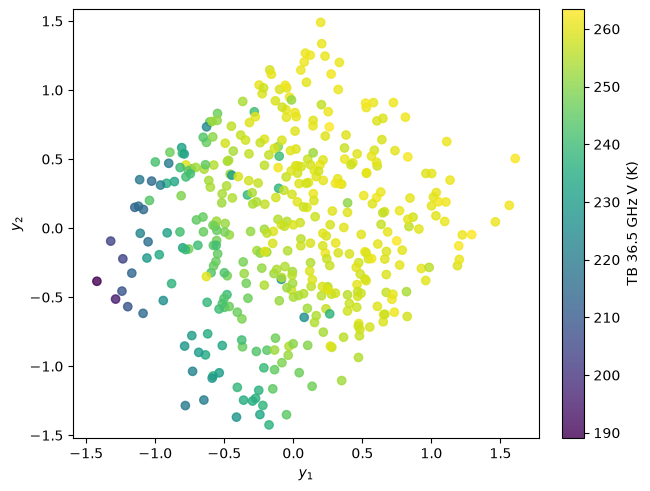

In [11]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=X, f=f36, dims=2, qoi_label='TB 36.5 GHz V (K)')
plt.close(fig)
fig

Against $y_1$ (range $-1.42$ to $1.61$) the samples follow a bent trend: $T_B$(36V) stays high for $y_1 > 0$, where the snow scatters little (90 % of those 193 samples have $T_B \ge$ 255.6 K, the highest 263.4 K; the lowest, 226.2 K, is a dense sample), and falls steeply to 189 K at the most scattering corner, with a wide vertical spread in between (correlation 0.735). The 41 dense samples (red circles) follow the same trend (correlation 0.758 among them, 0.761 among the others), but several lie below the band of the others: that is the dense-snow step, which the gradients do not see (quantified in the next cell). In the $(y_1, y_2)$ plot the colour changes along $y_1$ and also along $y_2$ for $y_1 < 0$: a second direction is needed where scattering is strong.

LOO R^2, quadratic in y1: 0.7014
LOO R^2, cubic in y1: 0.7329
LOO R^2, quadratic in (y1, y2): 0.8194
LOO R^2, cubic in (y1, y2): 0.8566
LOO R^2, cubic in all 5 inputs: 0.9250
LOO R^2, cubic in (y1, y2), the 359 samples below the dense-snow threshold only: 0.9270
dense samples, TB36V minus that fit: median -3.1 K, 15 of 41 below -5 K, lowest -27.6 K
n = 1: LOO R^2 cubic 0.7329 (check), cubic + step x (1, y): 0.7640
n = 2: LOO R^2 cubic 0.8566 (check), cubic + step x (1, y): 0.9222


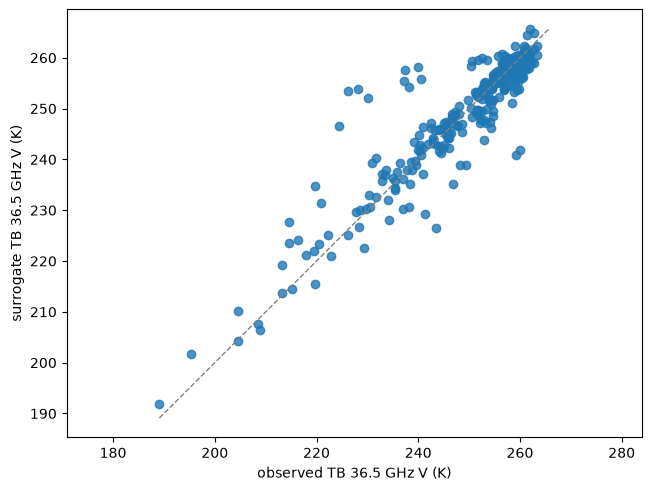

In [12]:
sub2 = ac.with_dimension(sub, 2)
fits = {'quadratic in y1': ac.fit_surrogate(X=X, f=f36, subspace=sub, kind='poly', degree=2) if sub.n == 1
        else ac.fit_surrogate(X=X, f=f36, subspace=ac.with_dimension(sub, 1), kind='poly', degree=2),
        'cubic in y1': ac.fit_surrogate(X=X, f=f36, subspace=ac.with_dimension(sub, 1), kind='poly', degree=3),
        'quadratic in (y1, y2)': ac.fit_surrogate(X=X, f=f36, subspace=sub2, kind='poly', degree=2),
        'cubic in (y1, y2)': ac.fit_surrogate(X=X, f=f36, subspace=sub2, kind='poly', degree=3),
        'cubic in all 5 inputs': ac.fit_surrogate(X=X, f=f36, space=space, subspace=None, kind='poly', degree=3)}
for k, s in fits.items():
    print(f'LOO R^2, {k}: {s.loo_r_squared:.4f}')
s_below = ac.fit_surrogate(X=X[~dense], f=f36[~dense], subspace=sub2, kind='poly', degree=3)
print(f'LOO R^2, cubic in (y1, y2), the {np.count_nonzero(~dense)} samples below the dense-snow threshold only: '
      f'{s_below.loo_r_squared:.4f}')
res_dense = f36[dense] - ac.predict(s_below, X[dense])
print(f'dense samples, TB36V minus that fit: median {np.median(res_dense):+.1f} K, '
      f'{np.count_nonzero(res_dense < -5)} of {dense.sum()} below -5 K, lowest {res_dense.min():+.1f} K')
# the step made explicit: cubic in y plus H(rho - rho*) (a + b.y); least squares, LOO R^2 from the hat matrix
def loo_r2(A, y):
    Q, _ = np.linalg.qr(A)
    lev, r = np.sum(Q**2, axis=1), y - Q @ (Q.T @ y)
    return 1 - np.sum((r / (1 - lev))**2) / np.sum((y - y.mean())**2)
def monomials(Yn, deg):
    cols = [np.ones(len(Yn))] + [np.prod(Yn[:, list(c)], axis=1) for d in range(1, deg + 1)
                                 for c in combinations_with_replacement(range(Yn.shape[1]), d)]
    return np.column_stack(cols)
Hd = dense.astype(float)[:, None]
for n_ in (1, 2):
    Yn = Y[:, :n_]
    A3 = monomials(Yn, 3)
    print(f'n = {n_}: LOO R^2 cubic {loo_r2(A3, f36):.4f} (check), cubic + step x (1, y): '
          f'{loo_r2(np.hstack([A3, Hd * monomials(Yn, 1)]), f36):.4f}')
fig, ax = ac.plotting.plot_surrogate_fit(fits['cubic in (y1, y2)'], X=X, f=f36, qoi_label='TB 36.5 GHz V (K)')
plt.close(fig)
fig

Leave-one-out $R^2$: a quadratic in $y_1$ 0.701, a cubic 0.733; a quadratic in $(y_1, y_2)$ 0.819, a cubic 0.857; a cubic in all five inputs 0.925. On the 359 samples below the dense-snow threshold the cubic in $(y_1, y_2)$ reaches 0.927, and the dense samples sit below that fit (median $-3.1$ K; 15 of 41 more than 5 K below, the lowest $-27.6$ K). So about 73 % of the variance of $T_B$(36V) is explained by one active variable and 86 % by two; most of the rest is the dense-snow step, which no smooth function of $(y_1, y_2)$ can represent. Making the step explicit shows this: a cubic in $(y_1, y_2)$ plus $H(\rho - 458.35)\,(a + b\,y_1 + c\,y_2)$, with $H$ the unit step, has LOO $R^2$ = 0.922 (against 0.857 without the step term), and in $y_1$ alone, with $H\,(a + b\,y_1)$, 0.764 (against 0.733). This is moderate low-dimensional structure, not the near-exact ridge of some smooth benchmark models.

### The gradient ratio GR(36/18)

Its gradient follows from the stored TB gradients by the chain rule, $\nabla\mathrm{GR} = 2\,(T_{18}\nabla T_{36} - T_{36}\nabla T_{18})/(T_{36}+T_{18})^2$.

/tmp/ipykernel_9916/571097836.py:1: AccuracyWarning: bootstrap eigenvector replicates are poorly aligned with the full-sample vectors (columns [1]); their components are ill-defined, e.g. near repeated eigenvalues [accuracy.unaligned_replicates]
  sgr = ac.active_subspace(space=space, X=X, f=fgr, grads=Ggr, estimator='as', nboot=500,


eigenvalues: [3.4648e-03 4.1817e-04 3.2525e-04 1.8276e-04 6.3673e-06]
n = 1; lambda1/lambda2 = 8.29, lambda2/lambda3 = 1.29; lambda1 share 0.788, lambda1+lambda2 0.883
w1: depth -0.340, density +0.383, temperature +0.063, radius -0.548, stickiness +0.659
w2: depth -0.372, density +0.247, temperature +0.098, radius -0.484, stickiness -0.747
|w1(GR) . w1(TB36V)| = 1.000; bootstrap mean subspace distance n = 1: 0.063, n = 2: 0.376
LOO R^2 cubic in y1: 0.7383, LOO R^2 cubic in (y1, y2): 0.8528


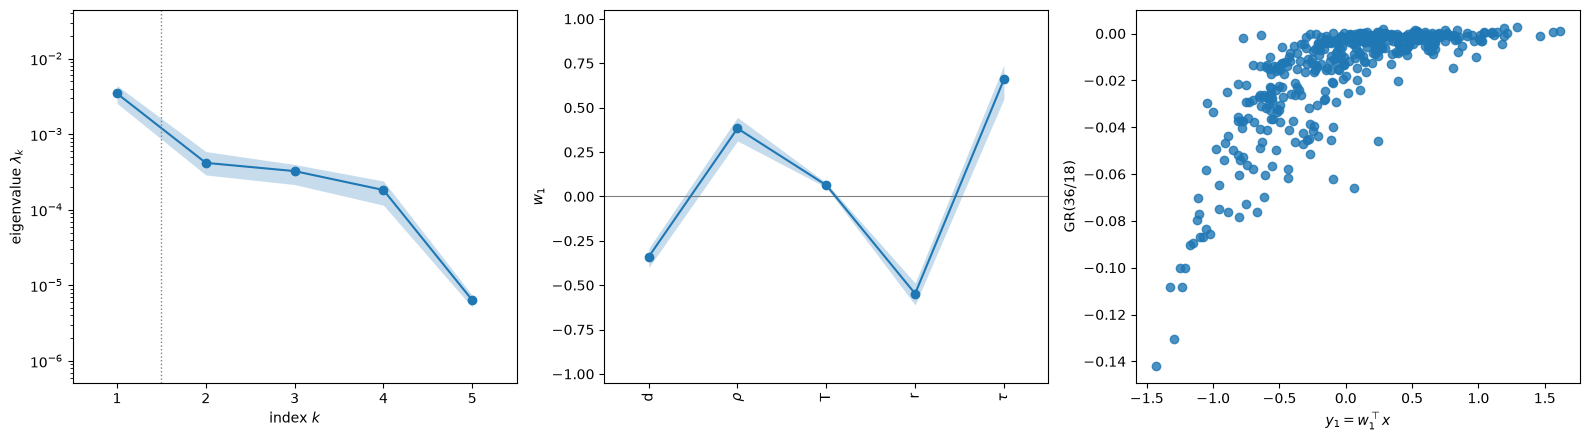

In [13]:
sgr = ac.active_subspace(space=space, X=X, f=fgr, grads=Ggr, estimator='as', nboot=500,
                         bootstrap_vectors=2, rng=SEED, qoi='GR(36/18)')
sgr = ac.orient(sgr, by='mean_gradient', grads=Ggr, columns=2)
lg, Wg = sgr.eigenvalues, sgr.eigenvectors
print('eigenvalues:', np.array2string(lg, precision=4))
print(f'n = {sgr.n}; lambda1/lambda2 = {lg[0] / lg[1]:.2f}, lambda2/lambda3 = {lg[1] / lg[2]:.2f}; '
      f'lambda1 share {lg[0] / lg.sum():.3f}, lambda1+lambda2 {lg[:2].sum() / lg.sum():.3f}')
for j in range(2):
    print(f'w{j + 1}:', ', '.join(f'{n} {v:+.3f}' for n, v in zip(names, Wg[:, j])))
print(f'|w1(GR) . w1(TB36V)| = {abs(Wg[:, 0] @ W[:, 0]):.3f}; '
      f'bootstrap mean subspace distance n = 1: {sgr.bootstrap_distances.mean(axis=0)[0]:.3f}, '
      f'n = 2: {sgr.bootstrap_distances.mean(axis=0)[1]:.3f}')
gfits = {k: ac.fit_surrogate(X=X, f=fgr, subspace=ac.with_dimension(sgr, n), kind='poly', degree=3)
         for k, n in [('cubic in y1', 1), ('cubic in (y1, y2)', 2)]}
print(', '.join(f'LOO R^2 {k}: {s.loo_r_squared:.4f}' for k, s in gfits.items()))
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
ac.plotting.plot_eigenvalues(sgr, ax=axs[0])
ac.plotting.plot_eigenvectors(sgr, indices=[0], labels=['d', r'$\rho$', 'T', 'r', r'$\tau$'],
                              interval='percentile', ax=[axs[1]])
ac.plotting.plot_sufficient_summary(sgr, X=X, f=fgr, dims=1, qoi_label='GR(36/18)', ax=axs[2])
fig.tight_layout()
plt.close(fig)
fig

GR(36/18) has $\lambda_1/\lambda_2 = 8.29$ and $\lambda_2/\lambda_3 = 1.29$; the first eigenvalue holds 78.8 % of the trace and the first two 88.3 %. Its first eigenvector is the same as that of $T_B$(36V) to the printed digits ($|\mathbf w_1^{\mathrm{GR}}\cdot\mathbf w_1| = 1.000$): stickiness $+0.659$, radius $-0.548$, density $+0.383$, depth $-0.340$, temperature $+0.063$. That is expected, since $T_B$(18V) varies much less than $T_B$(36V) here (sample standard deviations 1.47 K and 12.48 K, printed above), so GR(36/18) moves mostly with $T_B$(36V). The cubic surrogates have LOO $R^2$ 0.738 in $y_1$ and 0.853 in $(y_1, y_2)$. The summary plot saturates near GR $= 0$ for $y_1 > 0$; that flat region is where GR(36/18) carries little information about depth, in line with the paper's finding that GR(36/18) needs scattering snow (grain radius above about 0.2 mm; abstract, p. 6157) to retrieve depth.

### All twelve channels

The same estimator (no bootstrap) for every channel: eigenvalue ratios, the dimension chosen by the gap rule, the first eigenvector, and the leave-one-out $R^2$ of a cubic in $y_1$.

In [14]:
print('channel  lambda1/lambda2  lambda2/lambda3  n   w1 (d, rho, T, r, tau)            LOO R2 cubic in y1')
subs_all = {}
for c, k in ch.items():
    s = ac.active_subspace(space=space, X=X, f=TB[:, k], grads=G[:, k], estimator='as')
    s = ac.orient(s, by='mean_gradient', grads=G[:, k], columns=1)
    subs_all[c] = s
    l_, w_ = s.eigenvalues, s.eigenvectors[:, 0]
    r2 = ac.fit_surrogate(X=X, f=TB[:, k], subspace=ac.with_dimension(s, 1), kind='poly', degree=3).loo_r_squared
    print(f'{c:5s}  {l_[0] / l_[1]:12.1f}  {l_[1] / l_[2]:12.1f}     {s.n}   '
          + ' '.join(f'{v:+.3f}' for v in w_) + f'    {r2:.4f}')

channel  lambda1/lambda2  lambda2/lambda3  n   w1 (d, rho, T, r, tau)            LOO R2 cubic in y1
6V             98.0           2.8     1   -0.012 +0.998 +0.068 -0.008 +0.004    0.9947
6H           2151.4           9.2     1   +0.011 +1.000 +0.011 -0.001 +0.002    0.9985
10V             4.4          11.1     1   -0.060 +0.981 +0.144 -0.072 +0.088    0.9399
10H           455.1           2.0     1   +0.021 +1.000 +0.017 -0.007 +0.012    0.9924
18V             6.2           2.7     1   -0.247 +0.362 +0.061 -0.387 +0.809    0.6171
18H            11.2           5.7     1   +0.012 +0.986 +0.040 -0.086 +0.139    0.8741
23V             8.2           1.8     1   -0.273 +0.355 +0.050 -0.428 +0.784    0.6714
23H             3.8           5.8     1   -0.090 +0.852 +0.063 -0.274 +0.433    0.6240
36V             7.5           1.4     1   -0.339 +0.379 +0.066 -0.533 +0.673    0.7329
36H             7.1           1.3     1   -0.280 +0.467 +0.087 -0.542 +0.634    0.6845
89V             2.1           

The channels fall into three groups. At 6.9 and 10.7 GHz H (and 6.9 GHz V, $\lambda_1/\lambda_2 = 98$) the active subspace is one-dimensional and is the density axis ($|w_{\rho}| \ge 0.998$), with ratios 2151 (6H) and 455 (10H), and a cubic in $y_1$ fits with LOO $R^2 \ge 0.992$: as the paper notes (Sect. 4.1.1, pp. 6163–6165), at these frequencies density dominates the TB variance while the signal carries little information about the snowpack. 10V ($\lambda_1/\lambda_2 = 4.4$, then 11.1) and 18H (11.2) are still dominated by density (LOO $R^2$ 0.940 and 0.874). From 18V to 36H the first eigenvector turns to the scattering combination seen above (23H still leans on density, $+0.852$), with ratios 3.8–8.2 and LOO $R^2$ 0.62–0.73 in $y_1$. At 89 GHz the first two eigenvalues are close ($\lambda_1/\lambda_2 = 2.1$ and 1.9, then 7.7 and 6.4), so a two-dimensional subspace is the natural choice even though the gap rule picks $n = 1$; depth has the largest weight in $\mathbf w_1$ ($-0.888$ at 89V), and a cubic in $y_1$ reaches only LOO $R^2$ 0.40 (89V) and 0.51 (89H). The dense-snow step is largest at 36 and 89 GHz, which lowers these one-variable fits too.

### Comparison with the paper

The paper reports no active subspace; its quantitative results for this case are the EFAST indices of Fig. 3a (p. 6166), which print, for each channel, the parameter with the largest single (first-order) index with that index (SSI) and its total index (TSI). The EFAST sample size is not reported. To compare, we estimate first-order and total Sobol' indices from our data with a surrogate: orthonormal Legendre polynomials of total degree 5 in the normalized inputs (252 terms) plus a step at the dense-snow threshold whose size is a polynomial of degree 2 in all inputs (21 terms), fitted by least squares to the 400 values and the 2000 stored derivatives together (the step's derivative is left out, as in the stored gradients). The Sobol' indices of the surrogate are then computed exactly by tensor Gauss–Legendre quadrature, split at the threshold in density. We report 10-fold cross-validated $R^2$ of the fit (with and without the step term) and 95 % bootstrap intervals (200 resamples of the samples). These intervals cover sampling only, not the fit's truncation error.

In [15]:
from itertools import product
from numpy.polynomial import legendre as L

DEG, DEG_Q = 5, 2                                   # PCE degree; degree of the dense-snow step term
def multi_indices(deg):
    return np.array([a for a in product(range(deg + 1), repeat=5) if sum(a) <= deg])
alphas, alphas_q = multi_indices(DEG), multi_indices(DEG_Q)          # 252 and 21 terms
norm = np.sqrt(2 * np.arange(DEG + 1) + 1)          # orthonormal Legendre on U[-1, 1]
dP = np.array([np.r_[L.legder(np.eye(DEG + 1)[i]), 0.0] for i in range(DEG + 1)])
z_star = (sm.DENSE_THRESHOLD - sm.LOWER[1]) / ((sm.UPPER[1] - sm.LOWER[1]) / 2) - 1   # threshold, normalized


def basis(Z, alph, grads=True):
    # values (M, K) and normalized-coordinate gradients (M, 5, K) of the orthonormal Legendre basis
    V = np.stack([L.legvander(Z[:, j], DEG) * norm for j in range(5)], axis=1)               # (M, 5, DEG+1)
    Phi = np.prod(np.stack([V[:, j, alph[:, j]] for j in range(5)]), axis=0)
    if not grads:
        return Phi
    D = np.stack([np.stack([L.legval(Z[:, j], dP[i]) for i in range(DEG + 1)], 1) * norm
                  for j in range(5)], axis=1)
    dPhi = np.stack([D[:, j, alph[:, j]] * np.prod(np.stack([V[:, i, alph[:, i]] for i in range(5) if i != j]),
                                                   axis=0) for j in range(5)], axis=1)
    return Phi, dPhi


def features(Z, grads=True):
    # surrogate p(z) + H(z_rho - z*) q(z): a degree-5 PCE plus a step at the dense-snow threshold whose
    # size is a degree-2 polynomial; the step's derivative (a delta) is left out, like the stored gradients
    H = (Z[:, 1] > z_star).astype(float)
    if not grads:
        return np.hstack([basis(Z, alphas, False), H[:, None] * basis(Z, alphas_q, False)])
    (P1, dP1), (P2, dP2) = basis(Z, alphas), basis(Z, alphas_q)
    return np.hstack([P1, H[:, None] * P2]), np.concatenate([dP1, H[:, None, None] * dP2], axis=2)


Z = space.to_normalized(X)
Phi, dPhi = features(Z)
half = (sm.UPPER - sm.LOWER) / 2


def fit(rows, k, step=True):
    K = Phi.shape[1] if step else len(alphas)
    A = np.vstack([Phi[rows, :K], dPhi[rows, :, :K].reshape(-1, K)])
    b = np.r_[TB[rows, k], (G[rows, k] * half).reshape(-1)]
    return np.linalg.lstsq(A, b, rcond=None)[0]


# Sobol' indices of the fitted surrogate, exactly, by tensor Gauss-Legendre quadrature: 6 nodes per input
# (exact for the degree-10 products in the variances), 6 on each side of the dense-snow threshold in density
gx, gw = L.leggauss(6)
nodes, wts = [], []
for j in range(5):
    pieces = [(-1.0, z_star), (z_star, 1.0)] if j == 1 else [(-1.0, 1.0)]
    nodes.append(np.concatenate([(b - a) / 2 * gx + (a + b) / 2 for a, b in pieces]))
    wts.append(np.concatenate([gw * (b - a) / 4 for a, b in pieces]))        # weights of U[-1, 1], sum 1
shape = tuple(len(n) for n in nodes)
F_Q = features(np.stack(np.meshgrid(*nodes, indexing='ij'), -1).reshape(-1, 5), False)
W_Q = np.einsum('a,b,c,d,e->abcde', *wts)


def sobol(c):
    f = (F_Q @ c).reshape(shape)
    mu = np.sum(W_Q * f)
    V = np.sum(W_Q * (f - mu)**2)
    S1, ST = np.empty(5), np.empty(5)
    for j in range(5):
        other = tuple(i for i in range(5) if i != j)
        Ej = np.sum(W_Q * f, axis=other) / wts[j]                              # E[f | z_j] at the nodes
        S1[j] = np.sum(wts[j] * (Ej - mu)**2) / V
        wj = wts[j].reshape([-1 if i == j else 1 for i in range(5)])
        mj = np.sum(wj * f, axis=j, keepdims=True)                             # E[f | z_~j]
        ST[j] = np.sum(W_Q * (f - mj)**2) / V
    return S1, ST


rng = np.random.default_rng(SEED)
folds = np.arange(M) % 10                           # 10-fold cross-validation of the fit (values only)
paper = {'6V': ('density', .98, .99), '6H': ('density', .98, .99), '10V': ('density', .85, .90),
         '10H': ('density', .97, .99), '18V': ('density', .25, .54), '18H': ('density', .74, .84),
         '23V': ('radius', .19, .48), '23H': ('density', .40, .60), '36V': ('radius', .27, .51),
         '36H': ('radius', .44, .54), '89V': ('radius', .41, .48), '89H': ('radius', .49, .56)}
print(f'surrogate: degree-{DEG} Legendre PCE ({len(alphas)} terms) + dense-snow step x degree-{DEG_Q} '
      f'polynomial ({len(alphas_q)} terms), fitted to {M} values + {5 * M} derivatives; '
      f"Sobol' indices of the surrogate by quadrature ({np.prod(shape)} nodes)")
print('chan  CV R2 (no step term)  paper: top SSI TSI   | here: top by S1   S1 [95 %]           ST [95 %]'
      '            | here, paper\'s top input: S1, ST')
res_cmp = {}
for c, k in ch.items():
    cv = {}
    for step in (True, False):
        pred = np.empty(M)
        for q in range(10):
            cq = fit(np.flatnonzero(folds != q), k, step)
            pred[folds == q] = Phi[folds == q, :len(cq)] @ cq
        cv[step] = 1 - np.sum((pred - TB[:, k])**2) / np.sum((TB[:, k] - TB[:, k].mean())**2)
    c_full = fit(np.arange(M), k)
    S1, ST = sobol(c_full)
    boots = np.array([np.r_[sobol(fit(rng.integers(0, M, M), k))] for _ in range(200)])   # (200, 10)
    blo, bhi = np.percentile(boots, [2.5, 97.5], axis=0)
    top = int(np.argmax(S1))
    pj = names.index(paper[c][0])
    res_cmp[c] = (S1, ST, blo, bhi, cv)
    print(f'{c:4s} {cv[True]:6.4f} ({cv[False]:6.4f})   {paper[c][0]:8s} {paper[c][1]:.2f} {paper[c][2]:.2f} | '
          f'{names[top]:11s} {S1[top]:.2f} [{blo[top]:.2f}, {bhi[top]:.2f}]   {ST[top]:.2f} '
          f'[{blo[5 + top]:.2f}, {bhi[5 + top]:.2f}]   | {S1[pj]:.2f}, {ST[pj]:.2f}')
d1 = np.array([abs(round(res_cmp[c][0][names.index(paper[c][0])], 2) - paper[c][1]) for c in ch])
dT = np.array([abs(round(res_cmp[c][1][names.index(paper[c][0])], 2) - paper[c][2]) for c in ch])
agree = sum(names[int(np.argmax(res_cmp[c][0]))] == paper[c][0] for c in ch)
print(f"leading input (largest S1) equals the paper's in {agree} of 12 channels; |S1 - SSI| and |ST - TSI| "
      f"for the paper's top input: {np.sum(d1 <= 0.1) + np.sum(dT <= 0.1)} of 24 within 0.1, largest "
      f"{d1.max():.2f} (S1, {', '.join(c for c, v in zip(ch, d1) if v == d1.max())}) and {dT.max():.2f} (ST); "
      f"lowest CV R2 {min(v[4][True] for v in res_cmp.values()):.4f} with the step term, "
      f"{min(v[4][False] for v in res_cmp.values()):.4f} without")

surrogate: degree-5 Legendre PCE (252 terms) + dense-snow step x degree-2 polynomial (21 terms), fitted to 400 values + 2000 derivatives; Sobol' indices of the surrogate by quadrature (15552 nodes)
chan  CV R2 (no step term)  paper: top SSI TSI   | here: top by S1   S1 [95 %]           ST [95 %]            | here, paper's top input: S1, ST


6V   0.9999 (0.9998)   density  0.98 0.99 | density     0.99 [0.99, 0.99]   0.99 [0.99, 0.99]   | 0.99, 0.99


6H   1.0000 (1.0000)   density  0.98 0.99 | density     1.00 [1.00, 1.00]   1.00 [1.00, 1.00]   | 1.00, 1.00


10V  0.9970 (0.9953)   density  0.85 0.90 | density     0.89 [0.88, 0.90]   0.91 [0.91, 0.92]   | 0.89, 0.91


10H  0.9999 (0.9999)   density  0.97 0.99 | density     0.99 [0.99, 0.99]   0.99 [0.99, 0.99]   | 0.99, 0.99


...

23H  0.9804 (0.9439)   density  0.40 0.60 | density     0.52 [0.50, 0.53]   0.64 [0.63, 0.66]   | 0.52, 0.64


36V  0.9873 (0.9307)   radius   0.27 0.51 | radius      0.30 [0.29, 0.31]   0.50 [0.49, 0.52]   | 0.30, 0.50


36H  0.9854 (0.9074)   radius   0.44 0.54 | radius      0.32 [0.30, 0.32]   0.52 [0.51, 0.54]   | 0.32, 0.52


89V  0.9926 (0.9225)   radius   0.41 0.48 | radius      0.48 [0.46, 0.48]   0.53 [0.52, 0.54]   | 0.48, 0.53


89H  0.9928 (0.9138)   radius   0.49 0.56 | radius      0.53 [0.52, 0.54]   0.59 [0.58, 0.60]   | 0.53, 0.59
leading input (largest S1) equals the paper's in 12 of 12 channels; |S1 - SSI| and |ST - TSI| for the paper's top input: 22 of 24 within 0.1, largest 0.12 (S1, 23H, 36H) and 0.08 (ST); lowest CV R2 0.9726 with the step term, 0.9074 without


The cross-validated $R^2$ of the surrogate is 0.9726 or more in every channel (lowest 18V); without the step term it falls to 0.9074 (36H), so the step matters for the variance-based indices. The table copies the printed numbers of the paper's Fig. 3a and puts ours beside them (our 95 % bootstrap intervals in the cell output).

| Quantity | Paper value (Fig. 3a, EFAST) | Notebook value (Sobol' from the surrogate of the 400 samples) |
|---|---|---|
| 6V, 6H: top input, SSI / TSI | density, 0.98 / 0.99 | density, 0.99 / 0.99 and 1.00 / 1.00 |
| 10V: top input, SSI / TSI | density, 0.85 / 0.90 | density, 0.89 / 0.91 |
| 10H: top input, SSI / TSI | density, 0.97 / 0.99 | density, 0.99 / 0.99 |
| 18V: top input, SSI / TSI | density, 0.25 / 0.54 | density, 0.24 / 0.46 |
| 18H: top input, SSI / TSI | density, 0.74 / 0.84 | density, 0.83 / 0.87 |
| 23V: top input, SSI / TSI | radius, 0.19 / 0.48 | radius, 0.21 / 0.46 |
| 23H: top input, SSI / TSI | density, 0.40 / 0.60 | density, 0.52 / 0.64 |
| 36V: top input, SSI / TSI | radius, 0.27 / 0.51 | radius, 0.30 / 0.50 |
| 36H: top input, SSI / TSI | radius, 0.44 / 0.54 | radius, 0.32 / 0.52 |
| 89V: top input, SSI / TSI | radius, 0.41 / 0.48 | radius, 0.48 / 0.53 |
| 89H: top input, SSI / TSI | radius, 0.49 / 0.56 | radius, 0.53 / 0.59 |
| EFAST / Monte Carlo sample size | not reported | 400 samples with gradients (4400 SMRT runs) |
| Active subspace, $T_B$(36V) | not reported | $\lambda_1/\lambda_2 = 7.54$, $\lambda_2/\lambda_3 = 1.41$; $\mathbf w_1$ = (depth $-0.339$, density $+0.379$, temperature $+0.066$, radius $-0.533$, stickiness $+0.673$) |
| Active subspace, GR(36/18) | not reported | $\lambda_1/\lambda_2 = 8.29$; same $\mathbf w_1$ |

The leading input agrees in all 12 channels, and 22 of the 24 printed indices agree to within 0.1. The two exceptions are first-order indices: density at 23H (0.40 against 0.52) and radius at 36H (0.44 against 0.32), each 0.12 apart. They may come from settings the paper still does not state (DORT stream settings, ice microstructure, substrate properties; `DATA.md`), from EFAST's own sampling error, since the paper gives no EFAST sample size, or from our surrogate; we cannot separate these. Our bootstrap intervals have half-widths of 0.03 or less, which cover only our sampling, not the surrogate's truncation error.

### The dense-snow step and the gradient matrix

The step term of the 36V surrogate fitted above, the degree-2 polynomial $q(\mathbf z)$ multiplying $H(\rho - 458.35)$, estimates the jump of $T_B$(36V) across the threshold from the stored data alone. We evaluate it on the threshold face at the midpoint of the other inputs, at the deep, coarse-grained, sticky corner, and at 20 000 uniform points of the face. With the mean square jump $\mathrm E[\Delta^2]$ on the face we can also ask what $\mathbf C$ would be if the step were smoothed into a ramp of width $\varepsilon$ in density: in normalized coordinates (density 1/2 on $[-1, 1]$) the ramp adds about $\mathrm E[\Delta^2]/(2\varepsilon)$ to $C_{\rho\rho}$, to leading order. The cell repeats the finite-difference check of the load-data cell for reference.

In [16]:
k36 = ch['36V']
c36 = fit(np.arange(M), k36)                              # the 36V surrogate of the comparison above


def step_size(c, Zf):
    # q(z) on the threshold face: the jump TB(rho* +) - TB(rho* -) of the surrogate, K
    Zf = Zf.copy()
    Zf[:, 1] = z_star
    return basis(Zf, alphas_q, grads=False) @ c[len(alphas):]


z_mid = np.zeros((1, 5))
z_cor = space.to_normalized(np.array([[0.6, sm.DENSE_THRESHOLD, 240.0, 0.4, 0.1]]))
z_face = np.random.default_rng(SEED).uniform(-1, 1, (20000, 5))
jf = step_size(c36, z_face)
print(f'36V jump at the threshold, surrogate estimate: midpoint {step_size(c36, z_mid)[0]:+.2f} K, '
      f'corner (0.6 m, 240 K, 0.4 mm, 0.1) {step_size(c36, z_cor)[0]:+.2f} K; over the face: mean {jf.mean():+.2f} K, '
      f'rms {np.sqrt(np.mean(jf**2)):.2f} K, 5-95 % [{np.percentile(jf, 5):+.1f}, {np.percentile(jf, 95):+.1f}] K')
print(f'finite differences: density step {h_rho:.4f} kg/m^3, nearest sample {dist.min():.3f} kg/m^3 from the threshold')

# C if the step were a ramp of width eps (kg/m^3): add E[jump^2] / (2 eps_normalized) to C_rho,rho
C_pw = (W * lam) @ W.T                                    # the pathwise C-hat (normalized coordinates)
Ed2 = np.mean(jf**2)
print(f'E[jump^2] on the face {Ed2:.1f} K^2; pathwise C: lambda1/lambda2 {lam[0] / lam[1]:.2f}, '
      f'|w1 . e_rho| {abs(W[1, 0]):.3f}')
for eps in [87.5, 17.5, 1.75, h_rho]:
    eps_n = eps / ((sm.UPPER[1] - sm.LOWER[1]) / 2)
    Cs = C_pw.copy()
    Cs[1, 1] += Ed2 / (2 * eps_n)
    ls, Ws = np.linalg.eigh(Cs)
    ls, Ws = ls[::-1], Ws[:, ::-1]
    print(f'ramp width {eps:7.4f} kg/m^3: adds {Ed2 / (2 * eps_n):9.3g} to C_rho,rho; lambda1/lambda2 {ls[0] / ls[1]:7.2f}, '
          f'|w1 . e_rho| {abs(Ws[1, 0]):.3f}, |w1 . w1(pathwise)| {abs(Ws[:, 0] @ W[:, 0]):.3f}')


36V jump at the threshold, surrogate estimate: midpoint -7.50 K, corner (0.6 m, 240 K, 0.4 mm, 0.1) -59.55 K; over the face: mean -10.06 K, rms 14.20 K, 5-95 % [-31.1, +0.1] K
finite differences: density step 0.0175 kg/m^3, nearest sample 0.246 kg/m^3 from the threshold
E[jump^2] on the face 201.5 K^2; pathwise C: lambda1/lambda2 7.54, |w1 . e_rho| 0.379
ramp width 87.5000 kg/m^3: adds       202 to C_rho,rho; lambda1/lambda2    3.79, |w1 . e_rho| 0.468, |w1 . w1(pathwise)| 0.995
ramp width 17.5000 kg/m^3: adds  1.01e+03 to C_rho,rho; lambda1/lambda2    2.09, |w1 . e_rho| 0.882, |w1 . w1(pathwise)| 0.771
ramp width  1.7500 kg/m^3: adds  1.01e+04 to C_rho,rho; lambda1/lambda2   12.66, |w1 . e_rho| 0.999, |w1 . w1(pathwise)| 0.408
ramp width  0.0175 kg/m^3: adds  1.01e+06 to C_rho,rho; lambda1/lambda2 1224.73, |w1 . e_rho| 1.000, |w1 . w1(pathwise)| 0.380


The surrogate puts the 36V jump at $-7.50$ K at the midpoint of the other inputs and $-59.55$ K at the corner; direct SMRT runs (`DATA.md`, "Accuracy") give $-6.83$ K and $-54.0$ K there, and a mean of $-8.56$ K and an rms of 12.85 K over 40 random face points, against the surrogate's face mean $-10.06$ K and rms 14.20 K. So the estimate from the stored data has the right size, and the jump is mostly negative and grows with scattering. Smoothing it into a ramp changes $\mathbf C$ the more, the narrower the ramp: with a width of 87.5 kg m$^{-3}$ (a quarter of the range) $\lambda_1/\lambda_2$ becomes 3.79 and $|\mathbf w_1\cdot\mathbf e_\rho| = $ 0.468 (0.379 for the pathwise $\hat{\mathbf C}$); at 17.5 kg m$^{-3}$ 2.09 and 0.882; at 1.75 kg m$^{-3}$ 12.66 and 0.999; and if a stencil of the finite-difference step 0.0175 kg m$^{-3}$ straddled the step, 1225 and 1.000. A gradient measure that saw the step would therefore turn $\mathbf w_1$ towards density, and how far depends on an arbitrary smoothing width. The pathwise $\hat{\mathbf C}$ deliberately leaves the jump out; the jump shows in the values instead: in the residuals of the smooth ridge surrogates and the gain from the step term (LOO $R^2$ 0.857 → 0.922 in $(y_1, y_2)$), and in the Sobol' surrogate (lowest CV $R^2$ 0.9074 without the step term, 0.9726 with it).

### References

1. Z. Yan, Y. Ye, G. Heygster, B. Cheng, C. Gabarró, F. Hernández-Macià and X. Cheng, "Assessment of snow depth retrievability from passive microwave observations over Arctic sea ice: a global sensitivity analysis", *The Cryosphere* 20(11):6157–6180, 2026, doi:[10.5194/tc-20-6157-2026](https://doi.org/10.5194/tc-20-6157-2026). Supplement: doi:[10.5194/tc-20-6157-2026-supplement](https://doi.org/10.5194/tc-20-6157-2026-supplement). Preprint: EGUsphere, 2026, doi:[10.5194/egusphere-2026-1680](https://doi.org/10.5194/egusphere-2026-1680).
2. G. Picard, M. Sandells and H. Löwe, "SMRT: an active–passive microwave radiative transfer model for snow with multiple microstructure and scattering formulations (v1.0)", *Geoscientific Model Development* 11(7):2763–2788, 2018, doi:[10.5194/gmd-11-2763-2018](https://doi.org/10.5194/gmd-11-2763-2018). Code: <https://github.com/smrt-model/smrt> (LGPL-3.0).
3. P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, 2015, doi:[10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).
4. A. Saltelli, S. Tarantola and K. P.-S. Chan, "A quantitative model-independent method for global sensitivity analysis of model output", *Technometrics* 41(1):39–56, 1999, doi:[10.1080/00401706.1999.10485594](https://doi.org/10.1080/00401706.1999.10485594).
5. T. Markus and D. J. Cavalieri, "Snow depth distribution over sea ice in the Southern Ocean from satellite passive microwave data", in *Antarctic Sea Ice: Physical Processes, Interactions and Variability*, Antarctic Research Series 74:19–39, AGU, 1998, doi:[10.1029/AR074p0019](https://doi.org/10.1029/AR074p0019).
6. G. Picard, H. Löwe and C. Mätzler, "Brief communication: A continuous formulation of microwave scattering from fresh snow to bubbly ice from first principles", *The Cryosphere* 16(9):3861–3866, 2022, doi:[10.5194/tc-16-3861-2022](https://doi.org/10.5194/tc-16-3861-2022).

### Acknowledgments

From the paper: Z. Yan, Y. Ye and X. Cheng were funded by the National Natural Science Foundation of China (Grant No. 42576270), the Natural Science Foundation of Guangdong Province, China (Grant No. 2026A1515012280), and the Innovation Group Project of Southern Marine Science and Engineering Guangdong Laboratory (Zhuhai) (Grant No. 311021008); B. Cheng was funded by the Research Council of Finland project IceScales (Grant No. 364939). The data here were generated with SMRT, by G. Picard, M. Sandells, H. Löwe and contributors.

In [17]:
print(f'Total run time: {time.perf_counter() - t_start:.0f} s')

Total run time: 99 s
